# Actividad 1. Modelado predictivo de actividad hemolítica mediante aprendizaje automático

# Samuel Salazar Diaz

## Parte 1: Recolección y curación de datos peptídicos (HemoPI-1, HemoPI-2 y HemoPI-3)

**Referencia base:** Plisson, F., Ramírez-Sánchez, O., & Martínez-Hernández, C. (2020). Machine learning-guided discovery and design of non-hemolytic peptides. *Scientific Reports, 10*, 16581. https://doi.org/10.1038/s41598-020-73644-6

**Metodología:**
1. Monta Google Drive y localiza las carpetas `Act1_PSU/HemoPI-1/`, `HemoPI-2/` y `HemoPI-3/`.
2. Lee los 12 archivos FASTA y los convierte en tablas (`peptide_id`, `sequence`, `label`).
3. Une los archivos `model` (clase 0 + clase 1) en un conjunto de **entrenamiento** y los `validation` en un conjunto de **validación externa**, por separado para cada dataset.
4. Cura los datos: secuencias vacías, aminoácidos no estándar, duplicados, conflictos de etiqueta y solapamiento entre entrenamiento y validación.
5. Guarda las tablas limpias en Drive como CSV para usarlas en las siguientes partes (SMILES, Mordred, modelos).


**Convención de etiquetas:** `class0` = no hemolítico (label 0) y `class1` = hemolítico (label 1).

## 1. Montar Google Drive y definir rutas

In [1]:
# Montamos Google Drive para poder leer los archivos FASTA directamente desde Colab
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import os
import re
import pandas as pd

# Carpeta raíz de la actividad dentro de Drive (ajusta si la tuya está en otra ruta)
BASE_DIR = '/content/drive/MyDrive/Act1_PSU'

# Los tres datasets del artículo
DATASETS = ['HemoPI-1', 'HemoPI-2', 'HemoPI-3']

# Cada partición: 'model' será nuestro entrenamiento y 'validation' la validación externa
# Cada clase: 0 = no hemolítico, 1 = hemolítico
SPLITS = {'model': 'entrenamiento', 'validation': 'validacion'}
CLASSES = {0: 'no_hemolitico', 1: 'hemolitico'}

# Verificación rápida: confirmamos que las 12 rutas existen antes de continuar
faltantes = []
for ds in DATASETS:
    for split in SPLITS:
        for c in CLASSES:
            ruta = f'{BASE_DIR}/{ds}/{ds}_{split}_class{c}.fasta'
            if not os.path.exists(ruta):
                faltantes.append(ruta)

print('Archivos faltantes:', faltantes if faltantes else 'ninguno (los 12 archivos están disponibles)')

Archivos faltantes: ninguno (los 12 archivos están disponibles)


## 2. Función para leer archivos FASTA

Algunas secuencias podrían estar partidas en varias líneas, por eso se acumulan hasta encontrar el siguiente `>`.
Se implementa a mano (sin Biopython) para controlar exactamente qué se lee y detectar registros vacíos.

In [3]:
def leer_fasta(ruta):
    """
    Lee un archivo FASTA y devuelve una lista de tuplas (peptide_id, sequence).
    - peptide_id: texto del encabezado sin el '>' (ej. 'peptide_pm_1')
    - sequence: secuencia aminoacídica completa (unida si venía en varias líneas)
    """
    registros = []
    id_actual = None
    secuencia = []

    # errors='replace' evita que un carácter extraño rompa la lectura
    with open(ruta, 'r', encoding='utf-8', errors='replace') as f:
        for linea in f:
            linea = linea.strip()          # quita saltos de línea y espacios
            if not linea:
                continue                   # ignora líneas vacías
            if linea.startswith('>'):
                # Nuevo péptido: guardamos el anterior (si existía) y empezamos otro
                if id_actual is not None:
                    registros.append((id_actual, ''.join(secuencia)))
                id_actual = linea[1:].strip()
                secuencia = []
            else:
                secuencia.append(linea)

        # Guardamos el último péptido del archivo
        if id_actual is not None:
            registros.append((id_actual, ''.join(secuencia)))

    return registros

## 3. Cargar los 12 archivos en una única tabla

Se crea una fila por péptido con: dataset de origen, partición (entrenamiento/validación), nombre, secuencia, etiqueta numérica (0/1) y etiqueta en texto.
Mantener las columnas `dataset` y `split` permite separar después los datos sin perder trazabilidad.

In [4]:
filas = []

for ds in DATASETS:
    for split, nombre_split in SPLITS.items():
        for c, nombre_clase in CLASSES.items():
            ruta = f'{BASE_DIR}/{ds}/{ds}_{split}_class{c}.fasta'
            for pep_id, seq in leer_fasta(ruta):
                filas.append({
                    'dataset': ds,
                    'split': nombre_split,
                    'peptide_id': pep_id,
                    'sequence': seq,
                    'label': c,                    # 0 / 1 para los modelos
                    'activity': nombre_clase       # texto legible
                })

df_raw = pd.DataFrame(filas)
print('Dimensiones del dataset crudo:', df_raw.shape)
df_raw.head()

Dimensiones del dataset crudo: (3741, 6)


,dataset,split,peptide_id,sequence,label,activity
0,HemoPI-1,entrenamiento,peptide_nm_1,TKTTRNSPDSISIP,0,no_hemolitico
1,HemoPI-1,entrenamiento,peptide_nm_2,QRHPFKPKLHHID,0,no_hemolitico
2,HemoPI-1,entrenamiento,peptide_nm_3,KIPVVAAIHGACLGGGLELALACHQRV,0,no_hemolitico
3,HemoPI-1,entrenamiento,peptide_nm_4,NELPEPEQDNGGATESVKEQEMKW,0,no_hemolitico
4,HemoPI-1,entrenamiento,peptide_nm_5,YQIDQLSKMTYKNKSLNIHDLTA,0,no_hemolitico


### Resumen del dataset crudo (antes de curar)

In [6]:
# Conteo de péptidos por dataset, partición y clase: sirve para comprobar balance y que la carga fue correcta
resumen_raw = (df_raw
               .groupby(['dataset', 'split', 'activity'])
               .size()
               .unstack('activity', fill_value=0))
resumen_raw['total'] = resumen_raw.sum(axis=1)
resumen_raw

activity                hemolitico  no_hemolitico  total
dataset  split                                          
HemoPI-1 entrenamiento         442            442    884
         validacion            110            110    220
HemoPI-2 entrenamiento         442            370    812
         validacion            110             92    202
HemoPI-3 entrenamiento         708            590   1298
         validacion            177            148    325

In [7]:
# Longitud de las secuencias: ayuda a detectar valores atípicos o registros vacíos
df_raw['length'] = df_raw['sequence'].str.len()
df_raw.groupby(['dataset', 'split'])['length'].describe().round(1)

count  mean   std  min   25%   50%   75%    max
dataset  split                                                          
HemoPI-1 entrenamiento   884.0  20.6   9.7  4.0  14.0  18.0  25.0   98.0
         validacion      220.0  20.1   9.4  5.0  13.0  18.0  25.0   78.0
HemoPI-2 entrenamiento   812.0  19.9   9.4  2.0  13.0  18.0  25.0   98.0
         validacion      202.0  19.8   8.7  4.0  13.0  18.0  25.8   52.0
HemoPI-3 entrenamiento  1298.0  21.8  10.5  2.0  14.0  20.0  27.0   98.0
         validacion      325.0  22.0  11.7  5.0  14.0  20.0  27.0  133.0

## 4. Curación de los datos

El enunciado pide eliminar duplicados, secuencias incompletas o con valores faltantes. Se aplican estos pasos, **llevando un registro de cuántas filas se pierden en cada uno**:

1. Normalizar secuencias (mayúsculas, sin espacios).
2. Eliminar valores faltantes o secuencias vacías.
3. Eliminar secuencias con caracteres que no son los 20 aminoácidos estándar (X, B, Z, U, O, guiones, etc.), porque no se podrán convertir bien a SMILES ni a descriptores.
4. Detectar secuencias con **etiquetas contradictorias** (misma secuencia marcada como hemolítica y no hemolítica) y eliminarlas por completo ya que no hay forma de saber cuál etiqueta es correcta.
5. Eliminar duplicados exactos (misma secuencia y etiqueta) dentro de cada dataset y partición.
6. Eliminar del entrenamiento las secuencias que también aparecen en validación (**fuga de datos o *data leakage***), de modo que la validación externa sea realmente independiente.

In [8]:
# Aminoácidos estándar (código de una letra). Cualquier otro carácter se considera no estándar
AA_ESTANDAR = set('ACDEFGHIKLMNPQRSTVWY')

# Diccionario donde iremos anotando cuántas filas se eliminan en cada paso
log = []
def registrar(paso, antes, despues):
    log.append({'paso': paso, 'filas_antes': antes, 'filas_despues': despues, 'eliminadas': antes - despues})

df = df_raw.copy()

# --- Paso 1: normalización (mayúsculas y sin espacios internos) ---
df['sequence'] = df['sequence'].astype(str).str.upper().str.replace(r'\s+', '', regex=True)

# --- Paso 2: valores faltantes o secuencias vacías ---
n0 = len(df)
df = df.replace({'sequence': {'': pd.NA, 'NAN': pd.NA}})
df = df.dropna(subset=['peptide_id', 'sequence', 'label'])
registrar('Faltantes / vacías', n0, len(df))

# --- Paso 3: caracteres no estándar ---
n0 = len(df)
es_estandar = df['sequence'].apply(lambda s: set(s).issubset(AA_ESTANDAR))
no_estandar = df.loc[~es_estandar]
print(f'Secuencias con caracteres no estándar: {len(no_estandar)}')
if len(no_estandar):
    display(no_estandar[['dataset', 'split', 'peptide_id', 'sequence']].head(10))
df = df.loc[es_estandar]
registrar('Aminoácidos no estándar', n0, len(df))

Secuencias con caracteres no estándar: 0


In [9]:
# --- Paso 4: etiquetas contradictorias ---
# Una secuencia con más de una etiqueta distinta dentro del mismo dataset es ambigua y se elimina completa
n0 = len(df)
n_etiquetas = df.groupby(['dataset', 'sequence'])['label'].transform('nunique')
conflictos = df.loc[n_etiquetas > 1]
print(f'Filas con etiqueta contradictoria: {len(conflictos)}')
if len(conflictos):
    display(conflictos.sort_values(['dataset', 'sequence']).head(10))
df = df.loc[n_etiquetas == 1]
registrar('Etiquetas contradictorias', n0, len(df))

# --- Paso 5: duplicados exactos dentro de cada dataset y partición ---
n0 = len(df)
df = df.drop_duplicates(subset=['dataset', 'split', 'sequence', 'label'], keep='first')
registrar('Duplicados exactos (dataset + partición)', n0, len(df))

Filas con etiqueta contradictoria: 0


In [10]:
# --- Paso 6: fuga de datos entre entrenamiento y validación ---
# Si una secuencia está en ambas particiones del mismo dataset, la quitamos del entrenamiento
n0 = len(df)
seqs_validacion = df.loc[df['split'] == 'validacion', ['dataset', 'sequence']].drop_duplicates()
seqs_validacion['en_validacion'] = True

df = df.merge(seqs_validacion, on=['dataset', 'sequence'], how='left')
fuga = (df['split'] == 'entrenamiento') & (df['en_validacion'] == True)
print(f'Secuencias de entrenamiento que también están en validación: {fuga.sum()}')
df = df.loc[~fuga].drop(columns='en_validacion').reset_index(drop=True)
registrar('Fuga entrenamiento -> validación', n0, len(df))

# Registro completo de la curación
pd.DataFrame(log)

Secuencias de entrenamiento que también están en validación: 0


,paso,filas_antes,filas_despues,eliminadas
0,Faltantes / vacías,3741,3741,0
1,Aminoácidos no estándar,3741,3741,0
2,Etiquetas contradictorias,3741,3741,0
3,Duplicados exactos (dataset + partición),3741,3741,0
4,Fuga entrenamiento -> validación,3741,3741,0


## 5. Datos curados: entrenamiento y validación por dataset

Se separan las tablas finales. **Cada HemoPI se mantiene como un conjunto independiente**: son tareas de clasificación distintas (con distintos péptidos negativos) y mezclarlas podría introducir péptidos repetidos entre entrenamiento y validación.

In [11]:
# Tabla final con la longitud recalculada tras la curación
df['length'] = df['sequence'].str.len()

# Resumen final por dataset, partición y clase
resumen_final = (df.groupby(['dataset', 'split', 'activity'])
                   .size().unstack('activity', fill_value=0))
resumen_final['total'] = resumen_final.sum(axis=1)
resumen_final['pct_hemolitico'] = (resumen_final['hemolitico'] / resumen_final['total'] * 100).round(1)
resumen_final

activity                hemolitico  no_hemolitico  total  pct_hemolitico
dataset  split                                                          
HemoPI-1 entrenamiento         442            442    884            50.0
         validacion            110            110    220            50.0
HemoPI-2 entrenamiento         442            370    812            54.4
         validacion            110             92    202            54.5
HemoPI-3 entrenamiento         708            590   1298            54.5
         validacion            177            148    325            54.5

In [12]:
# Diccionarios {dataset: DataFrame} listos para las siguientes etapas (SMILES, Mordred, ML)
columnas = ['peptide_id', 'sequence', 'label', 'activity', 'length']

train = {ds: df[(df['dataset'] == ds) & (df['split'] == 'entrenamiento')][columnas].reset_index(drop=True)
         for ds in DATASETS}
valid = {ds: df[(df['dataset'] == ds) & (df['split'] == 'validacion')][columnas].reset_index(drop=True)
         for ds in DATASETS}

# Vista rápida del primer dataset
print('HemoPI-1 entrenamiento:', train['HemoPI-1'].shape, '| validación:', valid['HemoPI-1'].shape)
train['HemoPI-1'].head()

HemoPI-1 entrenamiento: (884, 5) | validación: (220, 5)


,peptide_id,sequence,label,activity,length
0,peptide_nm_1,TKTTRNSPDSISIP,0,no_hemolitico,14
1,peptide_nm_2,QRHPFKPKLHHID,0,no_hemolitico,13
2,peptide_nm_3,KIPVVAAIHGACLGGGLELALACHQRV,0,no_hemolitico,27
3,peptide_nm_4,NELPEPEQDNGGATESVKEQEMKW,0,no_hemolitico,24
4,peptide_nm_5,YQIDQLSKMTYKNKSLNIHDLTA,0,no_hemolitico,23


### Visualización rápida: balance de clases y distribución de longitudes

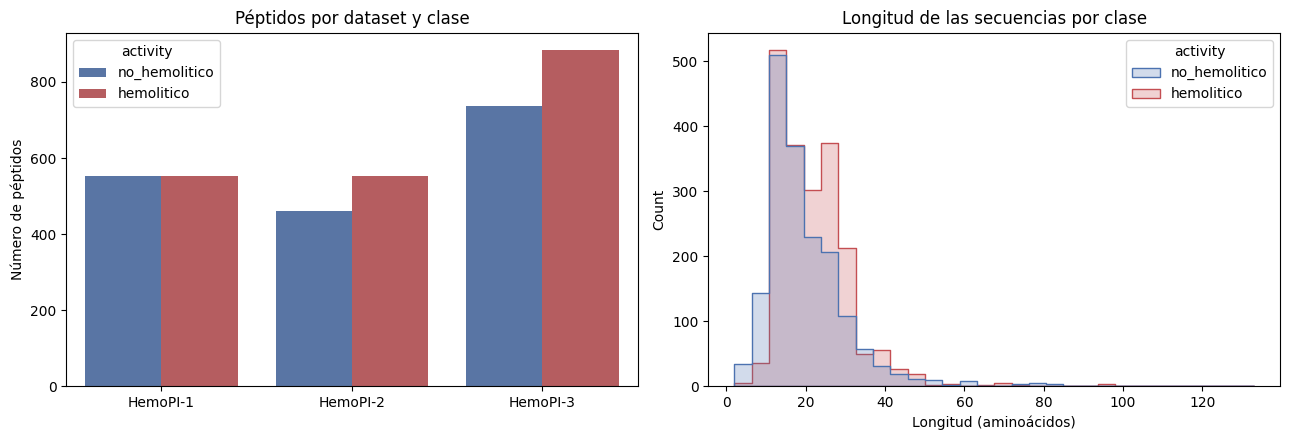

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# Balance de clases por dataset y partición
sns.countplot(data=df, x='dataset', hue='activity', ax=axes[0], palette=['#4C72B0', '#C44E52'])
axes[0].set_title('Péptidos por dataset y clase')
axes[0].set_xlabel('')
axes[0].set_ylabel('Número de péptidos')

# Distribución de la longitud de secuencia por clase
sns.histplot(data=df, x='length', hue='activity', bins=30, ax=axes[1],
             palette=['#4C72B0', '#C44E52'], element='step')
axes[1].set_title('Longitud de las secuencias por clase')
axes[1].set_xlabel('Longitud (aminoácidos)')

plt.tight_layout()
plt.show()

## 6. Guardar los datos curados en Drive

In [14]:
# Carpeta de salida dentro de Act1_PSU para no mezclar con los FASTA originales
OUT_DIR = f'{BASE_DIR}/datos_procesados'
os.makedirs(OUT_DIR, exist_ok=True)

for ds in DATASETS:
    train[ds].to_csv(f'{OUT_DIR}/{ds}_train.csv', index=False)
    valid[ds].to_csv(f'{OUT_DIR}/{ds}_validation.csv', index=False)

# Tabla de registro de curación también, útil para el informe
pd.DataFrame(log).to_csv(f'{OUT_DIR}/registro_curacion.csv', index=False)

print('Archivos guardados en:', OUT_DIR)
print(sorted(os.listdir(OUT_DIR)))

Archivos guardados en: /content/drive/MyDrive/Act1_PSU/datos_procesados
['HemoPI-1_train.csv', 'HemoPI-1_validation.csv', 'HemoPI-2_train.csv', 'HemoPI-2_validation.csv', 'HemoPI-3_train.csv', 'HemoPI-3_validation.csv', 'registro_curacion.csv']


## Siguiente paso

Con `train[ds]` y `valid[ds]` (o los CSV en `datos_procesados/`) se continúa con la Parte 2: conversión de secuencias a SMILES con **pyPept** y cálculo de descriptores con **Mordred**.